# 🐟 Dried Fish Quality Classification Pipeline
### ResNet50 · PyTorch · Google Colab

## 📦 Step 1 — Install & Imports

In [1]:
import os
import random
import copy
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Setup successful!")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)

Setup successful!
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device: cuda


## 📂 Dataset Upload

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Maldive_Fish.v3i.folder.zip to Maldive_Fish.v3i.folder.zip


## 📂 Step 3 — Dataset Extraction

In [3]:
import os
import zipfile
from pathlib import Path

zip_files = [name for name in uploaded if name.lower().endswith(".zip")]

if not zip_files:
    raise ValueError("Please upload your dataset as a ZIP file.")

ZIP_PATH = zip_files[0]
EXTRACT_PATH = Path("/content/dataset")
EXTRACT_PATH.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")
print("Dataset location:", EXTRACT_PATH)

for root, dirs, filenames in os.walk(EXTRACT_PATH):
    level = root.replace(str(EXTRACT_PATH), "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

Dataset extracted successfully!
Dataset location: /content/dataset
dataset/
  train/
    Medium_Quality/
    Low_Quality/
    High_Quality/
  valid/
    Medium_Quality/
    Low_Quality/
    High_Quality/
  test/
    Medium_Quality/
    Low_Quality/
    High_Quality/


## 🖼️ Step 4 — Dataset Loading & Preprocessing

In [4]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

DATASET_PATH = "/content/dataset"
IMG_SIZE = 224
BATCH_SIZE = 16

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_data = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "train"),
    transform=train_transform
)

valid_data = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "valid"),
    transform=eval_transform
)

test_data = datasets.ImageFolder(
    os.path.join(DATASET_PATH, "test"),
    transform=eval_transform
)

class_names = train_data.classes
num_classes = len(class_names)

assert valid_data.classes == class_names
assert test_data.classes == class_names
assert len(train_data) > 0 and len(valid_data) > 0 and len(test_data) > 0

print("Classes:", class_names)
print("Training images:", len(train_data))
print("Validation images:", len(valid_data))
print("Test images:", len(test_data))
print("Dataset loaded successfully!")

Classes: ['High_Quality', 'Low_Quality', 'Medium_Quality']
Training images: 1572
Validation images: 64
Test images: 64
Dataset loaded successfully!


## 🧠 Step 5 — ResNet50 Model Architecture & Data Loaders

In [5]:
import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import WeightedRandomSampler
import numpy as np

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_counts = np.bincount(
    [label for _, label in train_data.samples],
    minlength=num_classes
)

sample_weights = [
    1.0 / class_counts[label]
    for _, label in train_data.samples
]

sampler = WeightedRandomSampler(
    sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, sampler=sampler,
    num_workers=2, pin_memory=True
)
valid_loader = DataLoader(
    valid_data, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)

weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(in_features, num_classes)
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=0.0001, weight_decay=0.0001
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

print("ResNet50 model created!")
print("Device:", DEVICE)
print("Classes:", class_names)
print("Class counts:", class_counts)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 189MB/s]


ResNet50 model created!
Device: cuda
Classes: ['High_Quality', 'Low_Quality', 'Medium_Quality']
Class counts: [669 360 543]


## 🚀 Step 6 — Model Training

In [6]:
import copy

EPOCHS = 25
PATIENCE = 6

best_val_acc = 0.0
best_state = copy.deepcopy(model.state_dict())
best_epoch = 0
no_improve = 0

history = {
    "train_acc": [], "val_acc": [],
    "train_loss": [], "val_loss": []
}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch+1:02}/{EPOCHS} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Acc: {val_acc:.2%} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())
        no_improve = 0

        torch.save({
            "model_state_dict": best_state,
            "class_names": class_names,
            "best_val_acc": best_val_acc
        }, "/content/best_resnet50.pth")
    else:
        no_improve += 1

    if no_improve >= PATIENCE:
        print("Early stopping.")
        break

model.load_state_dict(best_state)

print(f"\nBest validation accuracy: {best_val_acc:.2%}")
print(f"Best epoch: {best_epoch}")
print("Model saved to /content/best_resnet50.pth")

Epoch 01/25 | Train Acc: 62.53% | Val Acc: 68.75% | Train Loss: 0.8451 | Val Loss: 0.7303
Epoch 02/25 | Train Acc: 80.03% | Val Acc: 70.31% | Train Loss: 0.5039 | Val Loss: 0.6541
Epoch 03/25 | Train Acc: 87.09% | Val Acc: 76.56% | Train Loss: 0.3479 | Val Loss: 0.5839
Epoch 04/25 | Train Acc: 90.52% | Val Acc: 78.12% | Train Loss: 0.2727 | Val Loss: 0.7077
Epoch 05/25 | Train Acc: 91.98% | Val Acc: 79.69% | Train Loss: 0.2198 | Val Loss: 0.6511
Epoch 06/25 | Train Acc: 93.38% | Val Acc: 71.88% | Train Loss: 0.1730 | Val Loss: 0.7877
Epoch 07/25 | Train Acc: 94.85% | Val Acc: 76.56% | Train Loss: 0.1548 | Val Loss: 0.7914
Epoch 08/25 | Train Acc: 95.48% | Val Acc: 79.69% | Train Loss: 0.1132 | Val Loss: 0.8190
Epoch 09/25 | Train Acc: 95.99% | Val Acc: 75.00% | Train Loss: 0.1132 | Val Loss: 0.7969
Epoch 10/25 | Train Acc: 96.06% | Val Acc: 78.12% | Train Loss: 0.1066 | Val Loss: 0.8233
Epoch 11/25 | Train Acc: 98.09% | Val Acc: 81.25% | Train Loss: 0.0697 | Val Loss: 0.8543
Epoch 12/2

## 🎯 Step 7 — Model Evaluation

In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import torch

checkpoint = torch.load(
    "/content/best_resnet50.pth",
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(y_true, y_pred)

print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

Final Test Accuracy: 85.94%

Classification Report:
                precision    recall  f1-score   support

  High_Quality       0.90      0.87      0.89        31
   Low_Quality       0.56      0.83      0.67         6
Medium_Quality       0.92      0.85      0.88        27

      accuracy                           0.86        64
     macro avg       0.79      0.85      0.81        64
  weighted avg       0.88      0.86      0.86        64



## 💾 Step 8 — Save & Download Trained Model

In [8]:
from google.colab import files

files.download("/content/best_resnet50.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🔲 Step 9 — Confusion Matrix


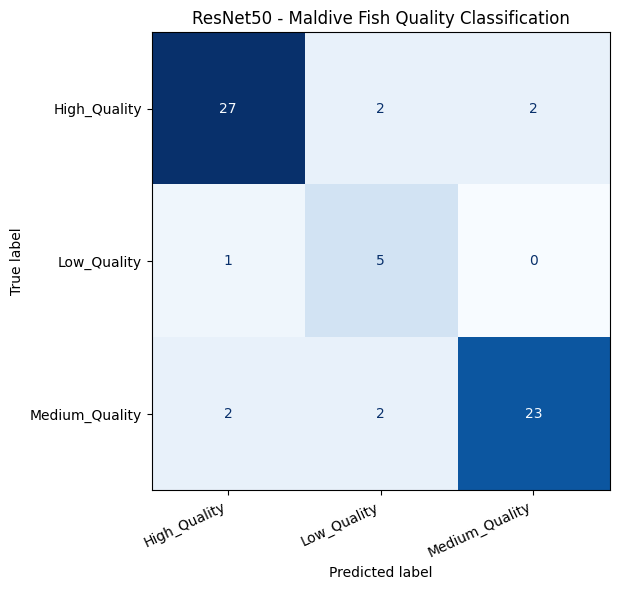

Class order: ['High_Quality', 'Low_Quality', 'Medium_Quality']
Total test images: 64
Correct predictions: 55
Test accuracy: 85.94%


In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("ResNet50 - Maldive Fish Quality Classification")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print("Class order:", class_names)
print("Total test images:", len(y_true))
print("Correct predictions:", np.trace(cm))
print("Test accuracy: {:.2f}%".format(
    100 * np.trace(cm) / np.sum(cm)
))

## 📈 Step 10 — Training & Validation Curves


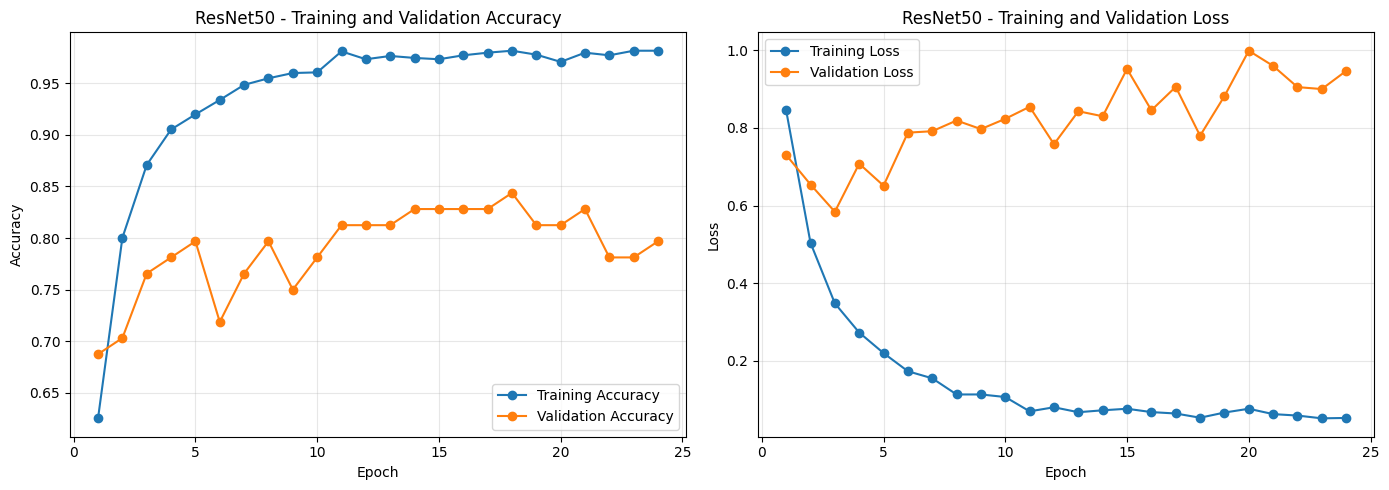

In [10]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_acc"]) + 1)

plt.figure(figsize=(14, 5))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_acc"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 - Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 - Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 🔍 Step 11 — Inference & Prediction Function

In [15]:
import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
from IPython.display import display as show_image

def predict_fish_quality(image_path, model, class_names, threshold=0.60):
    image = Image.open(image_path).convert("RGB")

    transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    image_tensor = transform(image).unsqueeze(0).to(DEVICE)

    model.eval()
    with torch.no_grad():
        logits = model(image_tensor)
        probabilities = F.softmax(logits, dim=1)[0]

    confidence, predicted_idx = probabilities.max(dim=0)
    confidence = confidence.item()
    predicted_class = class_names[predicted_idx.item()]

    prediction = (
        predicted_class
        if confidence >= threshold
        else "UNCERTAIN"
    )

    return {
        "prediction": prediction,
        "top_class": predicted_class,
        "confidence": confidence,
        "probabilities": {
            name: round(probabilities[i].item(), 4)
            for i, name in enumerate(class_names)
        }
    }

print("Prediction function ready!")

Prediction function ready!


## 🐠 Step 12 — Single Image Prediction

Saving Screenshot 2026-04-21 180827.png to Screenshot 2026-04-21 180827.png

Image: Screenshot 2026-04-21 180827.png
Prediction: High_Quality
Top class: High_Quality
Confidence: 68.96%
Class probabilities: {'High_Quality': 0.6896, 'Low_Quality': 0.0137, 'Medium_Quality': 0.2967}


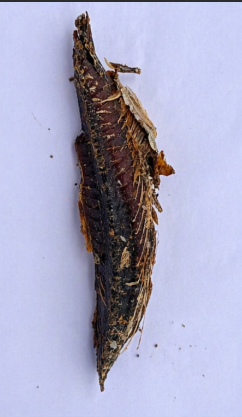

In [16]:
from google.colab import files
from IPython.display import display as show_image
from PIL import Image

uploaded_images = files.upload()

for image_path in uploaded_images.keys():
    try:
        result = predict_fish_quality(
            image_path,
            model,
            class_names,
            threshold=0.60
        )

        print("\nImage:", image_path)
        print("Prediction:", result["prediction"])
        print("Top class:", result["top_class"])
        print(f"Confidence: {result['confidence']:.2%}")
        print("Class probabilities:", result["probabilities"])

        show_image(Image.open(image_path).convert("RGB"))

    except Exception as error:
        print(f"Could not process {image_path}: {error}")

## 📋 Step 13 — Batch Prediction & CSV Export

In [17]:
import os
import torch
import pandas as pd
from PIL import Image
from google.colab import files
from IPython.display import display as show_image

def batch_predict(image_paths, model, class_names, threshold=0.60):
    results = []

    for image_path in image_paths:
        try:
            result = predict_fish_quality(
                image_path,
                model,
                class_names,
                threshold=threshold
            )

            row = {
                "Image": os.path.basename(image_path),
                "Prediction": result["prediction"],
                "Top_Class": result["top_class"],
                "Confidence_Percent": round(
                    result["confidence"] * 100, 2
                ),
                "Status": "Success"
            }

            for class_name, probability in result["probabilities"].items():
                row[f"{class_name}_Percent"] = round(
                    probability * 100, 2
                )

            results.append(row)

        except Exception as error:
            results.append({
                "Image": os.path.basename(image_path),
                "Prediction": "ERROR",
                "Top_Class": "",
                "Confidence_Percent": 0,
                "Status": str(error)
            })

    return pd.DataFrame(results)


print("Select multiple fish images to predict.")
uploaded_images = files.upload()

image_paths = list(uploaded_images.keys())

if image_paths:
    results_df = batch_predict(
        image_paths,
        model,
        class_names,
        threshold=0.60
    )

    print("\nBatch prediction results:")
    show_image(results_df)

    csv_path = "/content/maldive_fish_batch_predictions.csv"
    results_df.to_csv(csv_path, index=False)

    print("\nPrediction summary:")
    print(results_df["Prediction"].value_counts())

    files.download(csv_path)
else:
    print("No images uploaded.")

Select multiple fish images to predict.


Saving Screenshot 2026-04-21 190907.png to Screenshot 2026-04-21 190907.png
Saving WhatsApp Image 2026-04-07 at 08.45.09.jpeg to WhatsApp Image 2026-04-07 at 08.45.09.jpeg
Saving WhatsApp Image 2026-04-07 at 08.45.28.jpeg to WhatsApp Image 2026-04-07 at 08.45.28.jpeg
Saving WhatsApp Image 2026-04-07 at 08.45.50 (1).jpeg to WhatsApp Image 2026-04-07 at 08.45.50 (1).jpeg

Batch prediction results:


,Image,Prediction,Top_Class,Confidence_Percent,Status,High_Quality_Percent,Low_Quality_Percent,Medium_Quality_Percent
0,Screenshot 2026-04-21 190907.png,High_Quality,High_Quality,83.74,Success,83.74,0.88,15.38
1,WhatsApp Image 2026-04-07 at 08.45.09.jpeg,Medium_Quality,Medium_Quality,99.88,Success,0.04,0.08,99.88
2,WhatsApp Image 2026-04-07 at 08.45.28.jpeg,Medium_Quality,Medium_Quality,99.99,Success,0.00,0.00,99.99
3,WhatsApp Image 2026-04-07 at 08.45.50 (1).jpeg,Medium_Quality,Medium_Quality,99.90,Success,0.08,0.02,99.90



Prediction summary:
Prediction
Medium_Quality    3
High_Quality      1
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>